# Visualize Weka speed data

In [1]:
# Imports
import json

import pandas as pd
import plotly.express as px
import plotly.graph_objects as go
from plotly.subplots import make_subplots

from dataclasses import dataclass, asdict
from pathlib import Path

from weka_helpers import PrimitiveResultMap, ResultMap, convert_results_to_primitive, load_results_from_json

In [2]:
# Input parameters

input_dir = Path("/rubin/bench/weka")

input_files: list[Path] = input_dir.glob("*.json")

In [3]:
def result_map_to_dataframe(result_map: ResultMap) -> pd.DataFrame:
    print(result_map)
    rmd = {
        "sizes": result_map.sizes,
        "initial_speeds": result_map.initial_speeds_reported,
        "recheck_speeds": result_map.recheck_speeds_reported,
        "ratios": result_map.ratios_reported
    }
    return pd.DataFrame(data=rmd)
    
def plot_result(result_map: ResultMap) -> None:
    plot_recheck = any(result_map.recheck_speeds_reported)
    plot_ratio = any(result_map.ratios_reported)
    plot_individual_speeds(result_map, plot_recheck)
    

def plot_individual_speeds(result_map: ResultMap,
                          plot_recheck: bool) -> None:
    df = result_map_to_dataframe(result_map)
    fig = make_subplots(specs=[[{"secondary_y": True}]])
    xsz=len(df.initial_speeds)
    if plot_recheck:
        assert xsz == len(df.recheck_speeds)
    xrange=list(range(xsz))
    fig.add_trace(
        go.Scatter(
            x=xrange,
            y=df.initial_speeds,name="Initial speed"
        ),
        secondary_y=False
    )
    if plot_recheck:
        fig.add_trace(
            go.Scatter(
                x=xrange,
                y=df.recheck_speeds,
                name="Recheck speed"
            ),
            secondary_y=True
        )
    fig.update_layout(
        title_text = "Weka S3 Gateway speed"
    )
    fig.update_yaxes(title_text="Initial speed (bytes/s)",
                     secondary_y=False)
    if plot_recheck:
        fig.update_yaxes(title_text="Recheck speed (bytes/s)",
                         secondary_y=True)
    fig.show()    

ResultMap(display_name='datasets', dataset_name='visit_image', count=3, limit=10000, result_items=[ResultMapItem(url='https://sdfdatas3.slac.stanford.edu/rubin-dp2/LSSTCam/runs/DRP/DP2/v30_0_11/DM-55926/visit_image_rewrite/20260828T205140Z/visit_image/20250428/g/g_6/2025042800395/visit_image_LSSTCam_g_g_6_2025042800395_R01_S01_LSSTCam_runs_DRP_DP2_v30_0_11_DM-55926_visit_image_rewrite_20260828T205140Z.fits?AWSAccessKeyId=google_rsp_butler_server&Signature=53il%2Bt9hBzlsoDSopxWXdVGM%2B6Q%3D&Expires=1791611234', size=24719040, initial_start_time=None, initial_end_time=datetime.datetime(2026, 10, 10, 4, 47, 18, 823080, tzinfo=datetime.timezone.utc), initial_elapsed_time=None, recheck_start_time=datetime.datetime(2026, 10, 10, 4, 47, 22, 99328, tzinfo=datetime.timezone.utc), recheck_end_time=datetime.datetime(2026, 10, 10, 4, 47, 23, 372278, tzinfo=datetime.timezone.utc), recheck_elapsed_time=datetime.timedelta(0), initial_speed_reported=10590617.6, recheck_speed_reported=19818086.4, initi

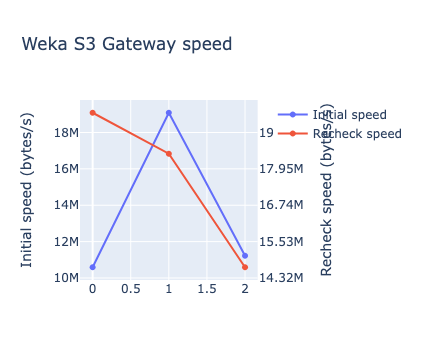

In [4]:
# Build a list of ResultMaps from all the files
res: list[ResultMap] = []
for fn in input_files:
    rms=load_results_from_json(fn)
    res.extend(rms)

for result_map in res:
    print(result_map)
    plot_result(result_map)